# Applying random forest propensity score matching to LaLonde-Dehejia-Wahba National Supported Work data

**Author:** Calvin Pan  
**Date created:** September 24, 2026  
**Date last modified:** September 24, 2026

This project was created as an assignment (Challenge #1) for my Impact Evaluations class (LPPA 7220) in UVA Batten's Master of Public Policy program.

The National Supported Work Demonstration (NSW) was a US federal program implemented in the mid-1970s that provided 6–18 months of work experience to individuals who had faced social and economic hardship. Data from the randomized evaluation of this program have been used in several influential econometrics papers testing whether non-experimental methods can recover experimental results:

1. [LaLonde (1986)](https://www.jstor.org/stable/1806062) argued that the non-experimental methods of the time could not reliably replicate the randomized, experimental results.
2. [Dehejia and Wahba (1999)](https://doi.org/10.1080/01621459.1999.10473858) showed that [propensity score matching](https://en.wikipedia.org/wiki/Propensity_score_matching) could come close to the experimental results. Their dataset, the *LaLonde-Dehejia-Wahba (LDW)* data, is now commonly used to test new econometric methods.
3. More recently, [Imbens and Xu (2025)](https://doi.org/10.1257/jep.20251440) show that the choice of estimator (propensity score matching, regression, weighting, or machine-learning methods) matters relatively little. What matters more is **overlap**: every observation should have a non-zero probability of being either treated or untreated. In practice, overlap is achieved by **trimming** the sample, i.e. dropping observations with extreme propensity scores. Imbens and Xu also argue that any estimate should be checked with placebo tests and sensitivity analyses.

In this exercise, I try to replicate Imbens and Xu's work. Specifically, I want to replicate their random forest propensity score pipeline, which they describe in this paragraph from their paper:

    "We begin by augmenting each nonexperimental sample with the experimental controls and estimating each unit’s probability of being in the experimental data using the generalized random forest technique. We then trim based on preset thresholds, which may exclude some treated units (Crump et al. 2009). Next, we re-estimate the propensity scores in the trimmed sample and perform 1:1 matching to refine the control group. This yields two sets of trimmed samples: one with experimental treated units and matched nonexperimental controls, and a second with treated and control units from the experiment, which serves as a benchmark. This two-step trimming and matching procedure improves overlap while preserving a comparison to an experimental benchmark."

 Imbens & Xu already provide a replication package in R, but I wanted to see if I could replicate their work in Python using SciKitLearn (the way I learned to do random forests). I hope to replicate their Panel B/D in Figure 1 and ATT for LDW-CPS in Figure 2 as precisely as possible. They also do placebo tests on this sample, which could be cool to explore as part of a future project.

**Data source:** [Imbens and Xu (2025) replication package](https://doi.org/10.3886/E232201V1)

### NOTE: To run this, you'll need to download the Imbens & Xu replication package, and rename it + place it in this repo.

I haven't included the Imbens & Xu package in this Github repo because of copyright restrictions.
**Data source:** [Imbens and Xu (2025) replication package](https://doi.org/10.3886/E232201V1)

Folder structure you'll need:   

challenge1/  
                    -- challenge1_pan_randomforests.ipynb  
                    -- imbens_xu_2025_replication (rename the replication package to this)  

### 0. Install packages

In [330]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Load & concatenate data
This loads & concatenates two datasets directly from the Imbens and Xu replication package: 
1. nsw_dw.dta, which is the LDW experimental sample,
2. cps_control.dta, which is based on
Westat’s Matched Current Population Survey–Social Security Administration File and includes all females or males under age 55 who met NSW's eligibility criteria. 

In [331]:
# Set directories
dir = "/Users/calvin/Library/Mobile Documents/com~apple~CloudDocs/Documents/Calvin/UVA/2026-27/LPPA_7220_Impact_Evals/python/impactevals/challenge1/"
replication_dir = dir + "imbens_xu_2025_replication/"

# Load data
nsw_dw = pd.read_stata(replication_dir + "data/dw/nsw_dw.dta", convert_categoricals=False)
cps_controls = pd.read_stata(replication_dir + "data/dw/cps_controls.dta", convert_categoricals=False)

In [332]:
# Concatenate the two datasets
combined = pd.concat([nsw_dw, cps_controls], ignore_index=True)
combined.tail(5) # Examine datasets

,data_id,treat,age,education,black,hispanic,married,nodegree,re74,re75,re78
16432,CPS1,0.0,22.0,12.0,1.0,0.0,0.0,0.0,3975.352051,6801.435059,2757.437988
16433,CPS1,0.0,20.0,12.0,1.0,0.0,1.0,0.0,1445.938965,11832.240234,6895.071777
16434,CPS1,0.0,37.0,12.0,0.0,0.0,0.0,0.0,1733.951050,1559.370972,4221.865234
16435,CPS1,0.0,47.0,9.0,0.0,0.0,1.0,1.0,16914.349609,11384.660156,13671.929688
16436,CPS1,0.0,40.0,10.0,0.0,0.0,0.0,1.0,13628.660156,13144.549805,7979.724121


### 2. Implement random forest propensity scoring on the NSW experimental sample (treated + controls) augmented with CPS controls:

"We begin by augmenting each nonexperimental sample with the experimental controls and estimating each unit’s probability of being in the experimental data using the generalized random forest technique" (Imbens & Xu 2025).

Following lalonde2_trim.R, the outcome for this first-stage model is NSW membership (1 = NSW treated or NSW control, 0 = CPS), not treatment. Imbens & Xu also include u74 and u75 (indicators for zero earnings in 1974 and 1975) as covariates.

In [333]:
# Create unemployment indicators: 1 if zero earnings that year
combined["u74"] = (combined["re74"] == 0).astype(int)
combined["u75"] = (combined["re75"] == 0).astype(int)

# Create NSW membership indicator: 1 if in the NSW experiment (treated or control), 0 if CPS
combined["nsw"] = (combined["data_id"] == "Dehejia-Wahba Sample").astype(int)

# Select features
covariates = ["age", "education", "black", "hispanic", "married", "nodegree", "re74", "re75", "u74", "u75"]
X = combined[covariates]   # Controls 
y = combined["nsw"]

y.value_counts() # Should be 445 NSW (185 treated + 260 controls), 15992 CPS

nsw
0    15992
1      445
Name: count, dtype: int64

In [334]:
from sklearn.ensemble import RandomForestClassifier

# Fit model:
model = RandomForestClassifier(n_estimators=500, # The more trees the better
                            min_samples_leaf=10, # A leaf has at least 10 people, so we can't have 1-person leaves; probabilites less extreme
                            oob_score=True, # We can't use a train test split because we want everything to have a propensity score, so use out-of-bag predictions instead.
                            random_state=100) 
model.fit(X, y)
combined["pscore"] = model.oob_decision_function_[:, 1] # Predict using model, and save predictions as column in df

In [335]:
# Checks
display(model.classes_)                         # should be array([0, 1]); confirms column 1 = NSW
display(combined.groupby(["data_id", "treat"])["pscore"].describe()) # Shows propensity score summary for NSW treated, NSW controls, and CPS

array([0, 1])

count      mean       std       min       25%  \
data_id              treat                                                    
CPS1                 0.0    15992.0  0.012990  0.058203  0.000000  0.000000   
Dehejia-Wahba Sample 0.0      260.0  0.555405  0.297270  0.006737  0.304996   
                     1.0      185.0  0.502630  0.292367  0.000186  0.273070   

                                 50%       75%       max  
data_id              treat                                
CPS1                 0.0    0.000063  0.003472  0.962797  
Dehejia-Wahba Sample 0.0    0.596215  0.819857  0.955119  
                     1.0    0.543263  0.748112  0.956114

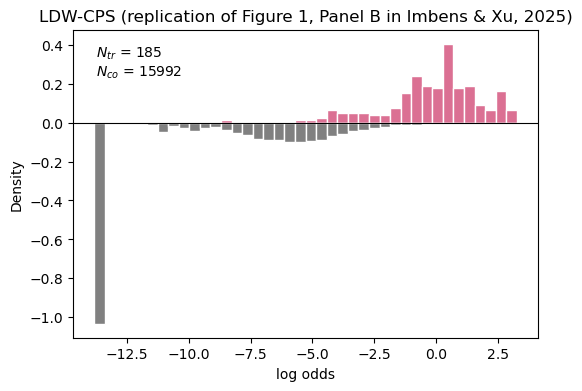

In [336]:
# Visualize propensity scores. Should replicate Figure 1, Panel B in Imbens & Xu
# Save logged version as log(p/1-p)
combined["clipped_pscore"] = np.clip(combined["pscore"], 1e-6, 1 - 1e-6)
combined["log_pscore"] = np.log(combined["clipped_pscore"] / (1 - combined["clipped_pscore"])) 

# Panel B compares NSW treated vs CPS controls (NSW experimental controls not shown)
treated_logodds = combined.loc[combined["treat"] == 1, "log_pscore"]
control_logodds = combined.loc[combined["data_id"] == "CPS1", "log_pscore"]
n_treated = len(treated_logodds)
n_control = len(control_logodds)

all_logodds = pd.concat([treated_logodds, control_logodds])
edges = np.linspace(np.min(all_logodds), np.max(all_logodds), 41)   # 41 edges → 40 equal-width bins; same edges for both groups
heights_tr, edges = np.histogram(treated_logodds, bins=edges, density=True)
heights_co, edges = np.histogram(control_logodds, bins=edges, density=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(edges[:-1], heights_tr, width=np.diff(edges), align="edge", color="palevioletred", edgecolor="white")  # Treated: bars go up
ax.bar(edges[:-1], -heights_co, width=np.diff(edges), align="edge", color="gray", edgecolor="white")          # Controls: negative heights, bars go down
ax.axhline(0, color="black", linewidth=0.8)

ax.set_xlabel("log odds")
ax.set_ylabel("Density")
ax.set_title("LDW-CPS (replication of Figure 1, Panel B in Imbens & Xu, 2025)")
ax.text(0.05, 0.95, f"$N_{{tr}}$ = {n_treated}\n$N_{{co}}$ = {n_control}", transform=ax.transAxes, va="top")
plt.show()

### 3. Trim data:

"We then trim based on preset thresholds, which may exclude some treated units (Crump et al. 2009)" (Imbens & Xu 2025).

We can look at the replication package to understand what thresholds Imbens & Xu use: they trim at ps ≤ 0.9 (see lalonde2_trim.R). Crump et al. 2009's rule is to trim to 0.1 ≤ ps ≤ 0.9. According to their comments, Imbens & Xu trim above 0.9 because above that point, only 4 control observations remain & have nothing to compare to; however, they don't trim below 0.1 because that would exclude too many observations.

In [337]:
# Trim data with ps above 0.9. Like lalonde2_trim.R, this yields two trimmed samples:
# 1) NSW treated + CPS controls, used for matching
combined_trimmed = combined[(combined["pscore"] <= 0.9) & ((combined["treat"] == 1) | (combined["data_id"] == "CPS1"))].copy()
# 2) NSW treated + NSW controls, the experimental benchmark
experimental_trimmed = combined[(combined["pscore"] <= 0.9) & (combined["nsw"] == 1)].copy()

display(combined_trimmed["treat"].value_counts())
display(experimental_trimmed["treat"].value_counts())

treat
0.0    15988
1.0      163
Name: count, dtype: int64

treat
0.0    222
1.0    163
Name: count, dtype: int64

### 4. Reestimate propensity score on the trimmed treated + CPS subset

In [338]:
# Select features
X = combined_trimmed[covariates]   # Controls 
y = combined_trimmed["treat"] # Now the outcome is treatment: NSW treated vs CPS controls

model.fit(X, y) # Use same model as before
combined_trimmed["pscore"] = model.oob_decision_function_[:, 1] # Predict using model, and save predictions as column in df

### 5. Using those new propensity scores, do 1:1 nearest neighbor matching without replacement.

Built my own loop to do this, since I couldn't find a package to do this without replacement.

For each treated unit:
1) Find the available control whose score is closest to this treated unit's score.
2) Record the pair.
3) Mark that control as used so no one else can take it.

In [339]:
# Drop units with a re-estimated score of exactly 0: no tree put them in a leaf with any treated unit, so they have no overlap.
# (Otherwise thousands of 0-score controls tie at distance 0, and argmin picks whichever comes first in the data.)
combined_trimmed = combined_trimmed[combined_trimmed["pscore"] > 0]

# Split trimmed data into treated and control DataFrames
# Sort treated rows from highest to lowest score, so that highest scores (hardest to match) get first pick.
# Sorting the DataFrame (not just the scores) keeps each score attached to its row.
treated = combined_trimmed[combined_trimmed["treat"] == 1].sort_values("pscore", ascending=False)
controls = combined_trimmed[combined_trimmed["treat"] == 0]

# Then, turn both treated and control scores into NumPy arrays
treated_scores = treated["pscore"].to_numpy()
control_scores = controls["pscore"].to_numpy()

# Set up other necessary arrays
available = np.ones(len(control_scores), dtype=bool)   # array of bool Trues, same length as array of control scores
matched = [] # Empty list to record positions of matched controls
matched_treated = [] # Positions of treated units that found a match within the caliper. matched[k] is the match for treated row matched_treated[k]

# Now the loop:
for i in range(len(treated_scores)):
    distances = np.abs(control_scores - treated_scores[i])   # Calculate distance to every control at once
    distances[~available] = np.inf                           # If control is not available, set their distance to infinity so that they are never selected
    j = np.argmin(distances)                                 # Record position of the smallest value
    available[j] = False                                     # Set closest to False
    matched.append(j)
    matched_treated.append(i)

In [340]:
# Concatenate matched treated rows with their matched controls (unmatched treated units are dropped)
combined_matched = pd.concat([treated.iloc[matched_treated], controls.iloc[matched]])

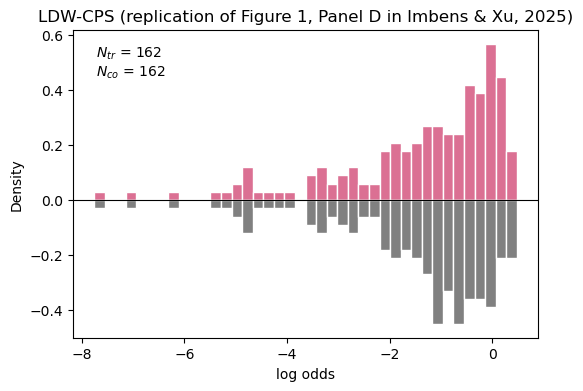

In [341]:
# Visualize propensity scores in matched sample. Should replicate Figure 1, Panel D in Imbens & Xu
# Save logged version as log(p/1-p)
combined_matched["clipped_pscore"] = np.clip(combined_matched["pscore"], 1e-6, 1 - 1e-6)
combined_matched["log_pscore"] = np.log(combined_matched["clipped_pscore"] / (1 - combined_matched["clipped_pscore"])) 

# Panel D compares NSW treated vs CPS controls (NSW experimental controls not shown)
treated_logodds = combined_matched.loc[combined_matched["treat"] == 1, "log_pscore"]
control_logodds = combined_matched.loc[combined_matched["data_id"] == "CPS1", "log_pscore"]
n_treated = len(treated_logodds)
n_control = len(control_logodds)

all_logodds = pd.concat([treated_logodds, control_logodds])
edges = np.linspace(np.min(all_logodds), np.max(all_logodds), 41)   # 41 edges → 40 equal-width bins; same edges for both groups
heights_tr, edges = np.histogram(treated_logodds, bins=edges, density=True)
heights_co, edges = np.histogram(control_logodds, bins=edges, density=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(edges[:-1], heights_tr, width=np.diff(edges), align="edge", color="palevioletred", edgecolor="white")  # Treated: bars go up
ax.bar(edges[:-1], -heights_co, width=np.diff(edges), align="edge", color="gray", edgecolor="white")          # Controls: negative heights, bars go down
ax.axhline(0, color="black", linewidth=0.8)

ax.set_xlabel("log odds")
ax.set_ylabel("Density")
ax.set_title("LDW-CPS (replication of Figure 1, Panel D in Imbens & Xu, 2025)")
ax.text(0.05, 0.95, f"$N_{{tr}}$ = {n_treated}\n$N_{{co}}$ = {n_control}", transform=ax.transAxes, va="top")
plt.show()

### 6. Calculate ATT 
This is just naive difference in re78 (income in 1978) between treated & control in the matched dataset.

In [342]:
treated_mean = combined_matched[(combined_matched["treat"] == 1)]["re78"].mean()
control_mean = combined_matched[(combined_matched["treat"] == 0)]["re78"].mean()


print("The naive difference in 1978 income between treated & control in the matched dataset is: $" + str(treated_mean - control_mean) )

The naive difference in 1978 income between treated & control in the matched dataset is: $1565.3882


### Conclusion:
We've been able to replicate Imbens & Xu's Figure 1, Panel B pretty faithfully. 
Our version of Imbens & Xu's Figure 1, Panel D looks a little different than theirs, 
which is likely due to a slightly different random forest package. Our ATT is also pretty 
close to the ~+$1,800 in Imbens & Xu's Figure 4.

A good next step for another project would be to replicate their placebo tests!